# Isobaric chain A = 128: energy vs Z, decay modes and β end-point energies

**Given** atomic masses (in u) for $_{50}$Sn … $_{56}$Ba, all with A = 128.

**Tasks**
1. Draw a diagram of energy (mass) versus atomic number Z.
2. Label the possible decay modes and justify them.
3. Find, where applicable, the maximum kinetic energy of the β particles.
4. Decide which nuclei are stable.

Because the masses are **atomic** masses (they include the electrons), the Q-values are:

| Decay | Condition / Q-value |
|---|---|
| β⁻ : $Z \to Z+1$ | $Q_{\beta^-} = [M(Z) - M(Z+1)]\,c^2 > 0$ |
| Electron capture (EC): $Z \to Z-1$ | $Q_{EC} = [M(Z) - M(Z-1)]\,c^2 > 0$ |
| β⁺ : $Z \to Z-1$ | $Q_{\beta^+} = [M(Z) - M(Z-1) - 2m_e]\,c^2 > 0$ |
| Double β⁻ : $Z \to Z+2$ | $Q_{\beta\beta} = [M(Z) - M(Z+2)]\,c^2 > 0$ |

The daughter nucleus is ~10⁵ times heavier than the electron, so its recoil energy is negligible: the **maximum kinetic energy of the β particle ≈ Q** (reached when the neutrino carries away almost no energy).

In [1]:
import sys

if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib"])

import numpy as np
import matplotlib.pyplot as plt

u_to_MeV = 931.494     # 1 u c^2 in MeV
me_u     = 0.000548580 # electron mass in u
me_MeV   = me_u * u_to_MeV
nA = 128

data = {  # Z: (symbol, atomic mass in u)
    50: ("Sn", 127.91047),
    51: ("Sb", 127.90907),
    52: ("Te", 127.90447),
    53: ("I",  127.90583),
    54: ("Xe", 127.90354),
    55: ("Cs", 127.90776),
    56: ("Ba", 127.90851),
}
Z    = np.array(sorted(data))
sym  = [data[z][0] for z in Z]
M    = np.array([data[z][1] for z in Z])
dM   = M - nA    #  Mass excess: dM(Z,A) = M(Z,A) - A * mu (in atomic mass units mu=1)
#Mmin = M.min()
#E    = (M - Mmin) * u_to_MeV          # energy relative to the lightest isobar, MeV

for z, s, m, dm in zip(Z, sym, M, dM):
    parity = ("even" if z % 2 == 0 else "odd") + "-" + ("even" if (nA - z) % 2 == 0 else "odd")
    print(f"{z:3d} {s:3s} M = {m:.5f} u   dM = {dm:.5f} u   ({parity}, N = {nA - z})")

 50 Sn  M = 127.91047 u   dM = -0.08953 u   (even-even, N = 78)
 51 Sb  M = 127.90907 u   dM = -0.09093 u   (odd-odd, N = 77)
 52 Te  M = 127.90447 u   dM = -0.09553 u   (even-even, N = 76)
 53 I   M = 127.90583 u   dM = -0.09417 u   (odd-odd, N = 75)
 54 Xe  M = 127.90354 u   dM = -0.09646 u   (even-even, N = 74)
 55 Cs  M = 127.90776 u   dM = -0.09224 u   (odd-odd, N = 73)
 56 Ba  M = 127.90851 u   dM = -0.09149 u   (even-even, N = 72)


## Q-values for every allowed single-step decay

In [2]:
decays = {}   # (parent Z) -> list of (mode, daughter Z, Q in MeV)

for z in Z:
    m = data[z][1]
    modes = []
    # beta-minus to Z+1
    if z + 1 in data:
        Q = (m - data[z + 1][1]) * u_to_MeV
        if Q > 0:
            modes.append(("β⁻", z + 1, Q))
    # EC and beta-plus to Z-1
    if z - 1 in data:
        Qec = (m - data[z - 1][1]) * u_to_MeV
        if Qec > 0:
            modes.append(("EC", z - 1, Qec))
            Qbp = Qec - 2 * me_MeV
            if Qbp > 0:
                modes.append(("β⁺", z - 1, Qbp))
    decays[z] = modes

print(f"2 m_e c^2 = {2*me_MeV:.3f} MeV\n")
for z in Z:
    s = data[z][0]
    if not decays[z]:
        print(f"{s}-{nA} : no single-β decay energetically allowed -> Stable")
    for mode, zd, Q in decays[z]:
        tail = "   -> max β kinetic energy ≈ Q" if mode in ("β⁻", "β⁺") else "   (no β emitted; neutrino + X-rays)"
        print(f"{s}-{nA} --{mode:2s}--> {data[zd][0]}-{nA} : Q = {Q:6.3f} MeV{tail}")

2 m_e c^2 = 1.022 MeV

Sn-128 --β⁻--> Sb-128 : Q =  1.304 MeV   -> max β kinetic energy ≈ Q
Sb-128 --β⁻--> Te-128 : Q =  4.285 MeV   -> max β kinetic energy ≈ Q
Te-128 : no single-β decay energetically allowed -> Stable
I-128 --β⁻--> Xe-128 : Q =  2.133 MeV   -> max β kinetic energy ≈ Q
I-128 --EC--> Te-128 : Q =  1.267 MeV   (no β emitted; neutrino + X-rays)
I-128 --β⁺--> Te-128 : Q =  0.245 MeV   -> max β kinetic energy ≈ Q
Xe-128 : no single-β decay energetically allowed -> Stable
Cs-128 --EC--> Xe-128 : Q =  3.931 MeV   (no β emitted; neutrino + X-rays)
Cs-128 --β⁺--> Xe-128 : Q =  2.909 MeV   -> max β kinetic energy ≈ Q
Ba-128 --EC--> Cs-128 : Q =  0.699 MeV   (no β emitted; neutrino + X-rays)


## Energy vs Z diagram

Odd-A chains lie on a single parabola. For **even A** the pairing term splits the points onto **two parabolas**: even-even nuclei (even Z here, since N = nA − Z is then even) lie lower, odd-odd nuclei (odd Z) lie higher. We fit a parabola through each set as a guide to the eye.

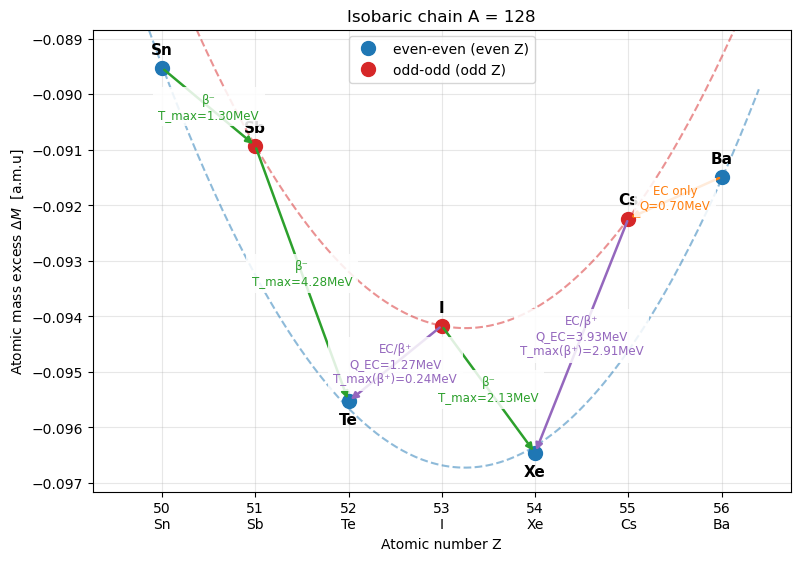

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))

even = Z % 2 == 0
odd  = ~even
zz = np.linspace(49.6, 56.4, 300)
for mask, col, lab in [(even, "tab:blue", "even-even (even Z)"), (odd, "tab:red", "odd-odd (odd Z)")]:
    c = np.polyfit(Z[mask], dM[mask], 2)
    ax.plot(zz, np.polyval(c, zz), "--", color=col, alpha=0.5)
    ax.plot(Z[mask], dM[mask], "o", ms=10, color=col, label=lab)

for z, s, dm in zip(Z, sym, dM):
    below = s in ("Te", "Xe")
    ax.annotate(
        s, xy=(z, dm),
        xytext=(0, -8 if below else 8), textcoords="offset points",
        ha="center", va="top" if below else "bottom",
        fontsize=11, fontweight="bold",
    )

colours = {"β⁻": "tab:green", "β⁺": "tab:purple", "EC": "tab:orange"}
for z in Z:
    modes = decays[z]
    has_bp = any(m == "β⁺" for m, _, _ in modes)
    for mode, zd, Q in modes:
        if mode == "EC" and has_bp:      # draw one arrow for EC/β⁺, label both
            continue
        dm0, dm1 = dM[Z == z][0], dM[Z == zd][0]
        ax.annotate("", xy=(zd, dm1 + 0.0), xytext=(z, dm0 - 0.0),
                    arrowprops=dict(arrowstyle="-|>", color=colours[mode], lw=1.8))
        if mode == "β⁺":
            Qec = [q for m, d, q in modes if m == "EC"][0]
            text = f"EC/β⁺\nQ_EC={Qec:.2f}MeV\nT_max(β⁺)={Q:.2f}MeV"
        elif mode == "EC":
            text = f"EC only\nQ={Q:.2f}MeV"
        else:
            text = f"β⁻\nT_max={Q:.2f}MeV"       

        xm, ym = (z + zd) / 2, (dm0 + dm1) / 2
        ax.text(xm, ym, text, color=colours[mode], fontsize=8.5, ha="center", va="center",
                bbox=dict(fc="white", ec="none", alpha=0.85))

ax.set_xlabel("Atomic number Z")
ax.set_ylabel(r"Atomic mass excess $\Delta M$  [a.m.u]")
ax.set_title("Isobaric chain A = 128")
ax.set_xticks(Z)
ax.set_xticklabels([f"{z}\n{s}" for z, s in zip(Z, sym)])
padding = 0.1 * (dM.max() - dM.min())
ax.set_ylim(dM.min() - padding, dM.max() + padding)
ax.grid(alpha=0.3)
ax.legend(loc="upper center")
#plt.tight_layout()
plt.show()